#Part C: Analysis & Visualisationn

## 1. Setup

In [19]:
import sqlite3, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from scipy import stats

import os
from pathlib import Path
print("Working folder:", Path.cwd())
print("Files here:")
for f in sorted(os.listdir(".")):
    print("  ", f)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries loaded.")

Working folder: c:\Users\user\Documents
Files here:
   .RData
   .Rhistory
   0xFFFFFFFF.docx
   4524595-hd_1920_1080_25fps.mp4
   5479720-uhd_3840_2160_25fps.mp4
   AI in East African Agriculture (AutoRecovered).docx
   Apple TV Installer.exe
   Arduino
   Ashley.jpg
   Assignment One Instructions.pdf
   Association_Rule_Mining_Practical.zip
   BG 41 PARTICIPANTS(2).docx
   Banking_system.py
   Bible Brunch Intro.mp4
   BigData_Lab1_Report.tex
   Bike_Sales.xlsx
   Billie+Eilish.jpg
   Billie.jpg
   Blackmagic Design
   Britney.html
   CHAPTER 1 MATRICES (1).pdf
   CHAPTER 1 MATRICES.pdf
   CHAPTER 3 VECTORS.pdf
   Castlevania [English]-S3E1-1080P.mp4
   ChromeSetup.exe
   Clustering.py
   Custom Office Templates
   Cyberrrr.jpg
   Data Mining and Wrangling Set
   Data Mining and Wrangling Set.zip
   Data Science For All Hunter Glanz.pdf
   Data Transformation-20260912
   Data Transformation-20260912.zip
   Data-mining-Assignment-Group-3-main
   Data-mining-Assignment-Group-3-main.zip

**Step 1.2 – Locate the database.** The function below looks for `jumia_eg.db` next to the notebook.
If yours lives somewhere else, write its full path in `DB_OVERRIDE`, for example `r"C:\Users\you\project\jumia_eg.db"`.

In [20]:
from pathlib import Path

DB_OVERRIDE = None         # <- put a full path here only if the automatic search fails
DB_NAME = "jumia_eg.db"

def find_db(override=None, name=DB_NAME):
    # 1. Explicit path, if given and valid
    if override:
        p = Path(override)
        if p.exists():
            return p.resolve()
        print(f"Warning: DB_OVERRIDE does not exist ({p}). Searching instead...")

    here = Path.cwd().resolve()
    searched = []

    # 2. The working folder, every parent folder, and a data/ subfolder of each
    for base in [here, *here.parents]:
        for p in (base / name, base / "data" / name):
            searched.append(str(p))
            if p.exists():
                return p

    # 3. Any subfolder of the working folder
    for p in here.rglob(name):
        return p.resolve()

    # 4. Common places in the user's home folder
    home = Path.home()
    for folder in ("Desktop", "Documents", "Downloads", "OneDrive"):
        base = home / folder
        if base.exists():
            for p in base.rglob(name):
                return p.resolve()

    raise FileNotFoundError(
        f"Could not find {name}.\n"
        f"Working folder: {here}\n"
        f"Also searched: {home}\\Desktop, Documents, Downloads\n"
        "Fix: copy jumia_eg.db into the working folder shown above, "
        "or set DB_OVERRIDE to its full path."
    )

DB_PATH = find_db(DB_OVERRIDE)
print("Using database:", DB_PATH)
print(f"Size: {DB_PATH.stat().st_size/1_048_576:.2f} MB")

Using database: C:\Users\user\Documents\Data-mining-Assignment-Group-3-main\Data-mining-Assignment-Group-3-main\jumia_eg.db
Size: 1.28 MB


**Our Helper functions.**
* `q(sql)` runs a SQL query and returns a pandas DataFrame. It opens and closes the connection each time, so nothing stays locked.
* `finish(fig, name)` tidies a figure, saves it to `charts/` and shows it.
* `short(text, n)` shortens long product names for chart labels.
* `log_fmt` writes log-scale axis values as normal numbers (e.g. 1,000 instead of 3).

In [21]:
def q(sql, params=()):
    """Run a SELECT query on the database and return a DataFrame."""
    with sqlite3.connect(DB_PATH) as con:
        return pd.read_sql_query(sql, con, params=params)

CHART_DIR = Path("charts")
CHART_DIR.mkdir(exist_ok=True)

def finish(fig, name):
    """Tidy layout, save the figure as PNG in charts/, and display it."""
    fig.tight_layout()
    fig.savefig(CHART_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def short(text, n=38):
    text = str(text)
    return text if len(text) <= n else text[: n - 1] + "…"

log_fmt = FuncFormatter(lambda x, _: f"{10**x:,.0f}")   # for axes holding log10(price)

def barh_labeled(ax, labels, values, color):
    """Horizontal bars at numeric positions, so two products with the same (shortened) name never merge."""
    pos = np.arange(len(values))
    ax.barh(pos, list(values), color=color)
    ax.set_yticks(pos)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()                      # first item on top

## 2. Interactive database dashboard

This dashboard reads the database **live** (press **Refresh** after loading new runs) and has three tabs:

1. **Tables & row counts** – every table and view in the database, its type, number of rows and number of columns, plus a bar chart of rows per table.
2. **Browse a table** – pick any table/view, choose how many rows to preview, and type a word to filter rows. The column list (name, type, primary key) is shown too.
3. **Data per day** – how many observations were stored for each collection day and category, and the load summary of each run.

> It uses `ipywidgets`, which works in JupyterLab, Jupyter Notebook, VS Code and Google Colab. If you see only text, run `pip install ipywidgets` and restart the kernel.

In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# ---------- data helpers (pure SQL, no widgets) ----------
def list_db_objects():
    """Every user table and view with its row count and column count."""
    with sqlite3.connect(DB_PATH) as con:
        objs = pd.read_sql_query(
            "SELECT name, type FROM sqlite_master "
            "WHERE type IN ('table','view') AND name NOT LIKE 'sqlite_%' "
            "ORDER BY type, name", con)
        n_rows, n_cols = [], []
        for name in objs["name"]:
            n_rows.append(con.execute(f'SELECT COUNT(*) FROM "{name}"').fetchone()[0])
            n_cols.append(len(con.execute(f'PRAGMA table_info("{name}")').fetchall()))
    objs["rows"] = n_rows
    objs["columns"] = n_cols
    return objs

def table_schema(name):
    with sqlite3.connect(DB_PATH) as con:
        info = pd.read_sql_query(f'PRAGMA table_info("{name}")', con)
    info["primary_key"] = info["pk"].map(lambda v: "yes" if v else "")
    info["not_null"] = info["notnull"].map(lambda v: "yes" if v else "")
    return info[["name", "type", "not_null", "primary_key"]]

def kpi_card(label, value):
    return (f"<div style='flex:1;min-width:130px;border:1px solid #d0d7de;border-radius:10px;"
            f"padding:10px 14px;background:#f6f8fa'>"
            f"<div style='font-size:12px;color:#57606a'>{label}</div>"
            f"<div style='font-size:22px;font-weight:600;color:#1f2328'>{value}</div></div>")

# ---------- widgets ----------
btn_refresh = widgets.Button(description="Refresh", icon="refresh", button_style="primary",
                             layout=widgets.Layout(width="120px"))
header_html = widgets.HTML()
out_overview, out_browse, out_days = widgets.Output(), widgets.Output(), widgets.Output()

dd_object = widgets.Dropdown(description="Table / view:", options=[],
                             style={"description_width": "95px"}, layout=widgets.Layout(width="420px"))
sl_rows   = widgets.IntSlider(value=20, min=5, max=500, step=5, description="Rows to show:",
                              continuous_update=False, style={"description_width": "95px"},
                              layout=widgets.Layout(width="420px"))
txt_filter = widgets.Text(description="Filter text:", placeholder="type a word, press Enter",
                          continuous_update=False, style={"description_width": "95px"},
                          layout=widgets.Layout(width="420px"))
out_schema, out_data = widgets.Output(), widgets.Output()

# ---------- renderers ----------
def render_overview():
    objs = list_db_objects()
    tables = objs[objs["type"] == "table"]
    n_obs_days = None
    try:
        n_obs_days = q("SELECT COUNT(DISTINCT scraped_date) AS n FROM observations")["n"][0]
    except Exception:
        pass
    modified = datetime.fromtimestamp(DB_PATH.stat().st_mtime).strftime("%d %b %Y %H:%M")
    cards = [
        kpi_card("Tables", len(tables)),
        kpi_card("Views", int((objs["type"] == "view").sum())),
        kpi_card("Rows in all tables", f"{int(tables['rows'].sum()):,}"),
        kpi_card("Collection days", n_obs_days if n_obs_days is not None else "–"),
        kpi_card("Database size", f"{DB_PATH.stat().st_size/1_048_576:.2f} MB"),
        kpi_card("Last modified", modified),
    ]
    header_html.value = (f"<div style='font-size:13px;color:#57606a;margin-bottom:6px'>"
                         f"<b>Database:</b> {DB_PATH.name}</div>"
                         f"<div style='display:flex;gap:10px;flex-wrap:wrap'>{''.join(cards)}</div>")
    with out_overview:
        clear_output(wait=True)
        try:                                   # coloured data bars (needs jinja2, which Jupyter installs)
            display(objs.style.hide(axis="index")
                    .bar(subset=["rows"], color="#8ecae6")
                    .format({"rows": "{:,}"}))
        except Exception:
            display(objs)
        fig, ax = plt.subplots(figsize=(8, 0.5 * max(len(tables), 3) + 1))
        t = tables.sort_values("rows")
        bars = ax.barh(t["name"], t["rows"], color="#219ebc")
        ax.bar_label(bars, labels=[f"{v:,}" for v in t["rows"]], padding=3)
        ax.set_xlabel("Number of rows")
        ax.set_title("Rows per table")
        ax.set_xlim(0, max(t["rows"].max() * 1.15, 1))
        fig.tight_layout()
        plt.show()
    # keep dropdown in sync with the database
    keep = dd_object.value
    dd_object.options = list(objs["name"])
    if keep in dd_object.options:
        dd_object.value = keep
    elif "observations" in dd_object.options:
        dd_object.value = "observations"
    elif len(dd_object.options):
        dd_object.value = dd_object.options[0]

def render_browse(_=None):
    name = dd_object.value
    if not name:
        return
    with out_schema:
        clear_output(wait=True)
        display(table_schema(name))
    with out_data:
        clear_output(wait=True)
        cols = table_schema(name)["name"].tolist()
        where, params = "", []
        text = txt_filter.value.strip()
        if text:
            where = " WHERE " + " OR ".join(f'CAST("{c}" AS TEXT) LIKE ?' for c in cols)
            params = [f"%{text}%"] * len(cols)
        with sqlite3.connect(DB_PATH) as con:
            total = con.execute(f'SELECT COUNT(*) FROM "{name}"{where}', params).fetchone()[0]
            data = pd.read_sql_query(f'SELECT * FROM "{name}"{where} LIMIT ?', con,
                                     params=params + [sl_rows.value])
        label = f"matching '{text}'" if text else "in total"
        print(f"{name}: {total:,} rows {label} · showing the first {len(data)}")
        display(data)

def render_days():
    with out_days:
        clear_output(wait=True)
        try:
            per_day = q("""
                SELECT o.scraped_date AS date, c.name AS category, COUNT(*) AS observations
                FROM observations o
                JOIN products p   ON p.product_id = o.product_id
                LEFT JOIN categories c ON c.category_id = p.category_id
                GROUP BY o.scraped_date, c.name ORDER BY o.scraped_date""")
            pivot = per_day.pivot(index="date", columns="category", values="observations").fillna(0).astype(int)
            pivot["TOTAL"] = pivot.sum(axis=1)
            display(pivot)
            fig, ax = plt.subplots(figsize=(8, 3.6))
            pivot.drop(columns="TOTAL").plot(kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.7)
            ax.axhline(500, color="crimson", ls="--", lw=1)
            ax.text(-0.45, 505, "assignment minimum: 500 products per run", color="crimson", fontsize=8)
            ax.set_ylabel("Products stored"); ax.set_xlabel("")
            ax.set_title("Products stored per collection day")
            ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left")
            plt.xticks(rotation=0)
            fig.tight_layout()
            plt.show()
            print("Load summary per run (table: runs)")
            display(q("SELECT run_id, source_file, is_sample, loaded_at, rows_raw, rows_clean, rows_rejected FROM runs"))
        except Exception as e:
            print("Could not build this tab:", e)

def refresh_all(_=None):
    render_overview()
    render_browse()
    render_days()

btn_refresh.on_click(refresh_all)
dd_object.observe(render_browse, names="value")
sl_rows.observe(render_browse, names="value")
txt_filter.observe(render_browse, names="value")

# ---------- layout ----------
tab_browse = widgets.VBox([
    widgets.HBox([widgets.VBox([dd_object, sl_rows, txt_filter]),
                  widgets.VBox([widgets.HTML("<b>Columns</b>"), out_schema], layout=widgets.Layout(margin="0 0 0 20px"))]),
    widgets.HTML("<hr style='margin:6px 0'>"),
    out_data,
])
tabs = widgets.Tab(children=[out_overview, tab_browse, out_days])
for i, title in enumerate(["Tables & row counts", "Browse a table", "Data per day"]):
    tabs.set_title(i, title)

dashboard = widgets.VBox([
    widgets.HTML("<h3 style='margin:0 0 6px 0'>📊 Jumia Egypt database dashboard</h3>"),
    header_html, widgets.HBox([btn_refresh], layout=widgets.Layout(margin="8px 0")), tabs,
])

refresh_all()
display(dashboard)

## 3. Load the clean data and check coverage

**Step 3.1 – Pull one analysis table from the database.**
We join `observations` (one row per product per day) with `products`, `categories`, `brands` and `runs`, so every row carries the product name, category, sub-category and brand.
We keep only real runs (`is_sample = 0`) so the first test run does not pollute the analysis.

In [23]:
obs = q("""
SELECT  o.obs_id, o.product_id, o.run_id, o.scraped_at, o.scraped_date,
        p.name, c.name AS category, p.subcategory, COALESCE(b.name, 'Unknown') AS brand,
        o.price_egp, o.old_price_egp, o.discount_pct, o.discount_pct_stated,
        o.is_discounted, o.price_is_range, o.rating, o.review_count,
        o.rank_in_category, o.page
FROM    observations o
JOIN    products   p ON p.product_id  = o.product_id
LEFT JOIN categories c ON c.category_id = p.category_id
LEFT JOIN brands     b ON b.brand_id    = p.brand_id
LEFT JOIN runs       r ON r.run_id      = o.run_id
WHERE   COALESCE(r.is_sample, 0) = 0
""")
obs["date"] = pd.to_datetime(obs["scraped_date"])
print(f"{len(obs):,} observations · {obs.product_id.nunique():,} distinct products · "
      f"{obs.date.nunique()} collection days")
obs.head()

4,139 observations · 993 distinct products · 6 collection days


,obs_id,product_id,run_id,scraped_at,scraped_date,name,category,subcategory,brand,price_egp,old_price_egp,discount_pct,discount_pct_stated,is_discounted,price_is_range,rating,review_count,rank_in_category,page,date
0,1,GE810DI06RAP4NAFAMZ,1,2026-10-13T19:09:04,2026-10-13,"Baby Bag for Mommies for Going Out, Picnics an...",Baby Products,Diapering,Generic,368.00,NaN,18.00,18.00,1,0,NaN,NaN,1,1,2026-10-13
1,2,PH604TG294ZNZNAFAMZ,1,2026-10-13T19:09:04,2026-10-13,Natural Baby Bottle 260ml – SCF033/17,Baby Products,Feeding,Philips Avent,"1,199.00",NaN,33.00,33.00,1,0,NaN,NaN,2,1,2026-10-13
2,3,GE810HA1NSE57NAFAMZ,1,2026-10-13T19:09:04,2026-10-13,Children's door barrier size from 75 cm to85 cm,Baby Products,Safety,Generic,"1,540.00",NaN,19.00,19.00,1,0,NaN,NaN,3,1,2026-10-13
3,4,GE810HA2DGEHVNAFAMZ,1,2026-10-13T19:09:04,2026-10-13,Freezer Door Lock - Adhesive child safety lock...,Baby Products,Safety,Generic,65.00,NaN,34.00,34.00,1,0,NaN,NaN,4,1,2026-10-13
4,5,GE810HA2E84GJNAFAMZ,1,2026-10-13T19:09:04,2026-10-13,"Child and Infant Safety Lock for Drawers, Cupb...",Baby Products,Safety,Generic,109.17,NaN,27.00,27.00,1,0,NaN,NaN,5,1,2026-10-13


**Step 3.2 – Coverage check (rubric: *Data collection*).**
The assignment asks for **7 daily runs with ≥ 500 products each**. This cell lists which days exist, how many products each run has, and flags anything missing so you can explain it in the report.

In [24]:
dates = sorted(obs["date"].unique())
first_day = pd.Timestamp(dates[0])
obs["day"] = (obs["date"] - first_day).dt.days + 1        # Day 1 = first run

per_run = (obs.groupby("scraped_date")
              .agg(products=("product_id", "nunique"),
                   categories=("category", "nunique"),
                   first_timestamp=("scraped_at", "min"))
              .reset_index())
display(per_run)

per_cat_run = (obs.pivot_table(index="scraped_date", columns="category", values="product_id",
                               aggfunc="nunique", fill_value=0))
print("Products collected per category in each run (a sudden drop usually means a page failed to load):")
display(per_cat_run)

expected = pd.date_range(dates[0], dates[-1])
missing = [d.strftime("%Y-%m-%d") for d in expected if d not in set(pd.to_datetime(dates))]
print(f"Runs found: {len(dates)}  (assignment asks for 7)")
print("Calendar days with NO run:", missing if missing else "none")
low = per_run[per_run.products < 500]
print("Runs below 500 products:", low.scraped_date.tolist() if len(low) else "none")

,scraped_date,products,categories,first_timestamp
0,2026-10-13,714,3,2026-10-13T19:09:04
1,2026-10-14,666,3,2026-10-14T14:06:46
2,2026-10-15,713,3,2026-10-15T16:10:48
3,2026-10-17,715,3,2026-10-17T02:50:17
4,2026-10-18,713,3,2026-10-18T06:40:08
5,2026-10-19,618,3,2026-10-19T07:36:46


Products collected per category in each run (a sudden drop usually means a page failed to load):


category,Baby Products,Health & Beauty,Phones & Tablets
scraped_date,,,
2026-10-13,224,250,240
2026-10-14,224,200,242
2026-10-15,224,250,239
2026-10-17,223,250,242
2026-10-18,224,250,239
2026-10-19,225,150,243


Runs found: 6  (assignment asks for 7)
Calendar days with NO run: ['2026-10-16']
Runs below 500 products: none


**Step 3.3 – Prepare the working tables.**

* `df` – the observation table without the few rows where the site showed a **price range** (`price_is_range = 1`). A range has no single price, so those rows would distort price statistics.
* `prod` – **one row per product** (median price, mean rank, mean rating, highest review count…). Questions about "the distribution of prices" should count each product once, not once per day.

In [25]:
n_range = int((obs.price_is_range == 1).sum())
df = obs[obs.price_is_range == 0].copy()
print(f"Excluded {n_range} price-range rows; {len(df):,} observations remain.")

df["discount_filled"] = df["discount_pct"].fillna(0)     # non-discounted = 0 % discount

CATS = sorted(df["category"].dropna().unique())
PALETTE = dict(zip(CATS, sns.color_palette("deep", len(CATS))))
DATES = sorted(df["date"].unique())

prod = (df.groupby("product_id")
          .agg(name=("name", "first"), category=("category", "first"),
               subcategory=("subcategory", "first"), brand=("brand", "first"),
               median_price=("price_egp", "median"),
               days_seen=("date", "nunique"),
               mean_rank=("rank_in_category", "mean"),
               mean_rating=("rating", "mean"),
               max_reviews=("review_count", "max"),
               mean_discount=("discount_filled", "mean"))
          .reset_index())
prod["log_price"] = np.log10(prod["median_price"])
print(f"{len(prod):,} products across {len(CATS)} categories: {', '.join(CATS)}")
prod.head()

Excluded 17 price-range rows; 4,122 observations remain.


990 products across 3 categories: Baby Products, Health & Beauty, Phones & Tablets


,product_id,name,category,subcategory,brand,median_price,days_seen,mean_rank,mean_rating,max_reviews,mean_discount,log_price
0,AF184ST0ST6LCNAFAMZ,Africana Luxury Microfiber Towel - NPC,Health & Beauty,Beauty & Personal Care,Africana,165.00,6,119.33,4.20,161.00,22.50,2.22
1,AF184ST17XWQANAFAMZ,Moroccan Bath Soap With Olive 300gm,Health & Beauty,Beauty & Personal Care,Africana,196.00,5,1.00,NaN,NaN,30.00,2.29
2,AF184ST1LU5SDNAFAMZ,Africana LEAVE IN NPC 225 Ml,Health & Beauty,Beauty & Personal Care,Africana,169.00,5,178.40,4.30,212.00,29.90,2.23
3,AF184ST318LRXNAFAMZ,Smooth Lotion Good Girl 250ml - Deep Hydration...,Health & Beauty,Beauty & Personal Care,Africana,199.00,5,23.40,NaN,NaN,30.00,2.30
4,AK648HB19QF2DNAFAMZ,On Call Plus Blood Glucose Test Strips - 50 St...,Health & Beauty,Health Care,On Call Plus,320.00,5,198.20,4.50,664.00,46.70,2.51


## 4. Core question (a) – What does the price distribution look like in each category? Identify outliers.

**Step 4.1 – Summary statistics per category** (one value per product: its median price across the days it was seen).
Large gaps between mean and median, and a high *skew*, tell us the distribution has a long right tail.

In [26]:
desc = (prod.groupby("category").median_price
        .agg(n="count", mean="mean", median="median", std="std", min="min",
             q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), max="max", skew="skew"))
desc["max_to_min_ratio"] = desc["max"] / desc["min"]
desc

,n,mean,median,std,min,q1,q3,max,skew,max_to_min_ratio
category,,,,,,,,,,
Baby Products,300,252.22,173.50,241.17,19.00,110.75,329.00,"1,540.00",2.73,81.05
Health & Beauty,329,157.80,127.00,151.91,9.99,57.00,205.00,"1,350.00",3.19,135.14
Phones & Tablets,361,"9,592.04",499.00,"22,915.40",13.21,160.00,"11,499.00","155,500.00",4.40,"11,771.39"


**Step 4.2 – Histograms (log scale).** Prices span several orders of magnitude, so a normal axis would squash almost everything into one bar. On a log axis the shape of each category becomes visible. The dashed line is the median.

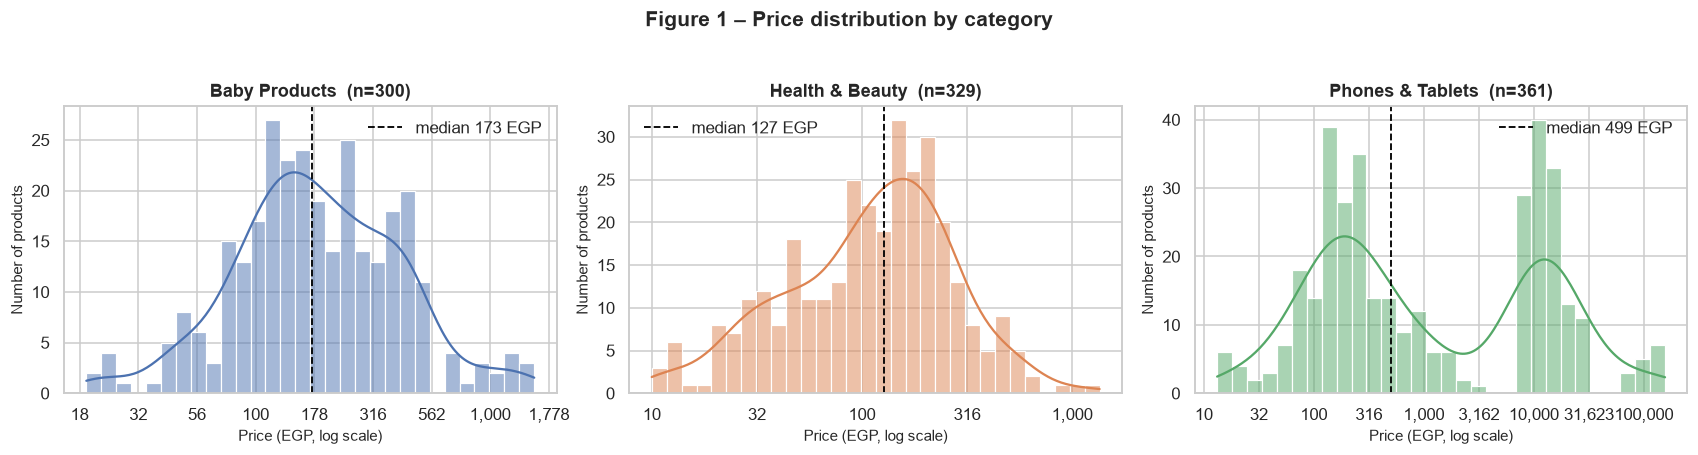

In [27]:
fig, axes = plt.subplots(1, len(CATS), figsize=(5.2 * len(CATS), 4), squeeze=False)
for ax, cat in zip(axes[0], CATS):
    s = prod.loc[prod.category == cat, "log_price"]
    sns.histplot(s, bins=30, kde=True, color=PALETTE[cat], ax=ax)
    ax.axvline(s.median(), color="black", ls="--", lw=1.2, label=f"median {10**s.median():,.0f} EGP")
    ax.xaxis.set_major_formatter(log_fmt)
    ax.set_title(f"{cat}  (n={len(s)})")
    ax.set_xlabel("Price (EGP, log scale)")
    ax.set_ylabel("Number of products")
    ax.legend(frameon=False)
fig.suptitle("Figure 1 – Price distribution by category", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig01_price_distribution")

**Step 4.3 – Box plots.** Left: all categories on one log axis. Right: the category with the widest price spread, split by sub-category, because a single category can hide very different kinds of products (for example phones vs. phone accessories).

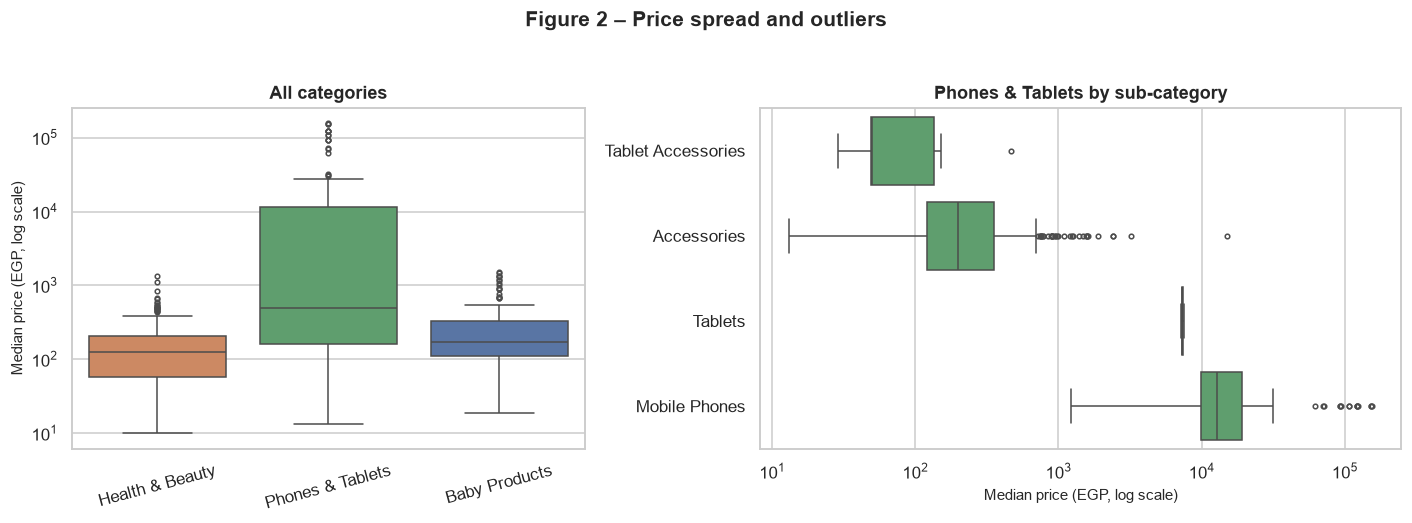

In [28]:
wide_cat = desc["max_to_min_ratio"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
sns.boxplot(data=prod, x="category", y="median_price", hue="category",
            palette=PALETTE, ax=axes[0], fliersize=3, legend=False)
axes[0].set_yscale("log")
axes[0].set_title("All categories")
axes[0].set_xlabel(""); axes[0].set_ylabel("Median price (EGP, log scale)")
axes[0].tick_params(axis="x", rotation=15)

sub = prod[prod.category == wide_cat]
order = sub.groupby("subcategory").median_price.median().sort_values().index
sns.boxplot(data=sub, y="subcategory", x="median_price", order=order, color=PALETTE[wide_cat],
            ax=axes[1], fliersize=3)
axes[1].set_xscale("log")
axes[1].set_title(f"{wide_cat} by sub-category")
axes[1].set_xlabel("Median price (EGP, log scale)"); axes[1].set_ylabel("")
fig.suptitle("Figure 2 – Price spread and outliers", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig02_price_boxplots")

**Step 4.4 – Identify the outliers.**
A category such as *Phones & Tablets* mixes very different things (a phone holder costing a few dozen EGP and a handset costing over a hundred thousand EGP), so one set of "normal" limits for the whole category would be meaningless. We therefore apply the standard **IQR rule** *within each sub-category* (a product is an outlier if it lies more than 1.5 × IQR below Q1 or above Q3), on **log-prices** because prices are strongly right-skewed. Sub-categories with fewer than 20 products are pooled into an "other" group of their category.

In [29]:
MIN_GROUP = 20
grp_size = prod.groupby(["category", "subcategory"]).product_id.transform("count")
prod["fence_group"] = np.where(grp_size >= MIN_GROUP,
                               prod.category + " / " + prod.subcategory.fillna("n/a"),
                               prod.category + " / (other sub-categories)")

fences = (prod.groupby("fence_group").log_price
          .agg(n="count", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)))
fences["iqr"] = fences.q3 - fences.q1
fences["lower_EGP"] = 10 ** (fences.q1 - 1.5 * fences.iqr)
fences["upper_EGP"] = 10 ** (fences.q3 + 1.5 * fences.iqr)

prod = prod.join(fences[["lower_EGP", "upper_EGP"]], on="fence_group")
prod["outlier"] = np.select([prod.median_price > prod.upper_EGP, prod.median_price < prod.lower_EGP],
                            ["high", "low"], default="")

outlier_summary = (prod.groupby("category")
                   .agg(products=("product_id", "count"),
                        high_outliers=("outlier", lambda s: (s == "high").sum()),
                        low_outliers=("outlier", lambda s: (s == "low").sum())))
outlier_summary["outlier_pct"] = 100 * (outlier_summary.high_outliers + outlier_summary.low_outliers) / outlier_summary.products
print("Outliers per category (rule applied inside each sub-category):")
display(outlier_summary)
print("Limits used per group (EGP):")
display(fences[["n", "lower_EGP", "upper_EGP"]])

for cat in CATS:
    top = (prod[(prod.category == cat) & (prod.outlier != "")]
           .sort_values("median_price", ascending=False)
           [["name", "subcategory", "brand", "median_price", "upper_EGP", "outlier"]]
           .assign(name=lambda d: d["name"].map(lambda s: short(s, 55))))
    print(f"\n{cat}: most extreme outliers (up to 5 highest and 3 lowest)")
    display(pd.concat([top.head(5), top.tail(3)]).drop_duplicates() if len(top) else "no outliers")

Outliers per category (rule applied inside each sub-category):


,products,high_outliers,low_outliers,outlier_pct
category,,,,
Baby Products,300,3,9,4.00
Health & Beauty,329,5,4,2.74
Phones & Tablets,361,22,10,8.86


Limits used per group (EGP):


,n,lower_EGP,upper_EGP
fence_group,,,
Baby Products / (other sub-categories),48,29.73,735.14
Baby Products / Bathing & Skin Care,126,28.89,770.91
Baby Products / Diapering,98,48.63,"1,467.65"
Baby Products / Feeding,28,9.23,"13,818.46"
Health & Beauty / (other sub-categories),23,40.71,634.20
Health & Beauty / Beauty & Personal Care,285,10.73,"1,203.30"
Health & Beauty / Oral Care,21,6.40,242.14
Phones & Tablets / (other sub-categories),10,2.60,"6,606.67"
Phones & Tablets / Accessories,212,23.62,"1,801.97"



Baby Products: most extreme outliers (up to 5 highest and 3 lowest)


,name,subcategory,brand,median_price,upper_EGP,outlier
434,Children's door barrier size from 75 cm to85 cm,Safety,Generic,"1,540.00",735.14,high
139,"Lucid – Latest Edition Mom Essentials Bag, Wat...",Strollers & Accessories,Lucid,"1,290.00",735.14,high
144,MOMO Go Soccer Ball (Professional Football-FIF...,Baby & Toddler Toys,MOMO,"1,080.00",735.14,high
968,White Adult Wipes 24 Pack – Durable Microfiber...,Diapering,White,45.00,"1,467.65",low
965,White ADULT WIPES 24 XL GENTLE ALL OVER WIPES-...,Diapering,White,45.00,"1,467.65",low
479,One Piece Of Baby Nail Clipper - Unisex-multi ...,Bathing & Skin Care,Generic,22.00,770.91,low
898,Superkids Superkids Hygiene Water Wipes 20 Wipes,Diapering,Superkids,20.00,"1,467.65",low
470,Baby Bath Shower Cap - blue,Bathing & Skin Care,Generic,19.00,770.91,low



Health & Beauty: most extreme outliers (up to 5 highest and 3 lowest)


,name,subcategory,brand,median_price,upper_EGP,outlier
574,Grey Pearl Daimond Extrait De Parfum 100ml For...,Beauty & Personal Care,IBRAQ,"1,350.00","1,203.30",high
858,"Sensodyne Toothpaste Rapid Action, 75 ml *6",Oral Care,Sensodyne,582.00,242.14,high
857,Sensodyne Toothpaste Deep Clean Gel - 100 ml -...,Oral Care,Sensodyne,492.00,242.14,high
859,Sensodyne Toothpaste Multi-Care + Whitening -1...,Oral Care,Sensodyne,492.00,242.14,high
141,Plan A Silicone Gel Flexible Upper and Lower T...,Oral Care,Plan A,250.00,242.14,high
447,Wood Back Massager for Instant Relief and Vers...,Wellness & Relaxation,Generic,11.99,634.20,low
493,Glue Nails Double Face - 24 Pieces,Beauty & Personal Care,Generic,9.99,"1,203.30",low
425,Flea Durable Double Sided Nit Comb Lice Detect...,Beauty & Personal Care,Generic,9.99,"1,203.30",low



Phones & Tablets: most extreme outliers (up to 5 highest and 3 lowest)


,name,subcategory,brand,median_price,upper_EGP,outlier
30,Iphone 18 Pro - 1TB - 5G Mobile Phone - Glacier,Mobile Phones,Apple,"155,500.00","50,517.27",high
31,Iphone 18 Pro - 1TB - 5G Mobile Phone - Burgundy,Mobile Phones,Apple,"152,999.00","50,517.27",high
33,Iphone 18 Pro - 1TB - 5G Mobile Phone - Silver,Mobile Phones,Apple,"152,749.50","50,517.27",high
38,Iphone 18 Pro - 256GB - 5G Mobile Phone - Burg...,Mobile Phones,Apple,"124,000.00","50,517.27",high
35,Iphone 18 Pro - 512GB - 5G Mobile Phone - Burg...,Mobile Phones,Apple,"122,222.00","50,517.27",high
375,Mini Phone Stand Holder – Universal Adjustable...,Accessories,Generic,17.00,"1,801.97",low
320,Mini Foldable Phone Stand Colorful Portable Mo...,Accessories,Generic,16.00,"1,801.97",low
293,Taha Offer Mobile Slot Cleaning Brush - 1 Piece,Accessories,Generic,13.21,"1,801.97",low


## 5. Core question (b) – Is there a relationship between price and rating, or between review count and rank/popularity?

**How we measure it.** Ratings are ordinal (1–5) and prices are very skewed, so we use **Spearman's rank correlation (ρ)**, which does not assume a straight-line relationship.
`ρ` runs from −1 to +1; the *p-value* tells us whether the relationship could just be chance (p < 0.05 = unlikely to be chance).
Only products that actually have a rating are used (many new items have none). Because a rating based on 1–2 reviews is unreliable, we also repeat the test using only products with **≥ 10 reviews**.

In [30]:
rated = prod.dropna(subset=["mean_rating"])

rows = []
for cat, g in rated.groupby("category"):
    rho, p = stats.spearmanr(g.median_price, g.mean_rating)
    g10 = g[g.max_reviews >= 10]
    rho10, p10 = stats.spearmanr(g10.median_price, g10.mean_rating) if len(g10) > 5 else (np.nan, np.nan)
    rows.append({"category": cat, "n_rated": len(g), "rho_all": rho, "p_all": p,
                 "n_10plus_reviews": len(g10), "rho_10plus": rho10, "p_10plus": p10})
price_rating = pd.DataFrame(rows).set_index("category")
price_rating

,n_rated,rho_all,p_all,n_10plus_reviews,rho_10plus,p_10plus
category,,,,,,
Baby Products,217,0.10,0.14,117,0.19,0.04
Health & Beauty,250,0.17,0.01,227,0.21,0.00
Phones & Tablets,177,0.29,0.00,55,0.29,0.03


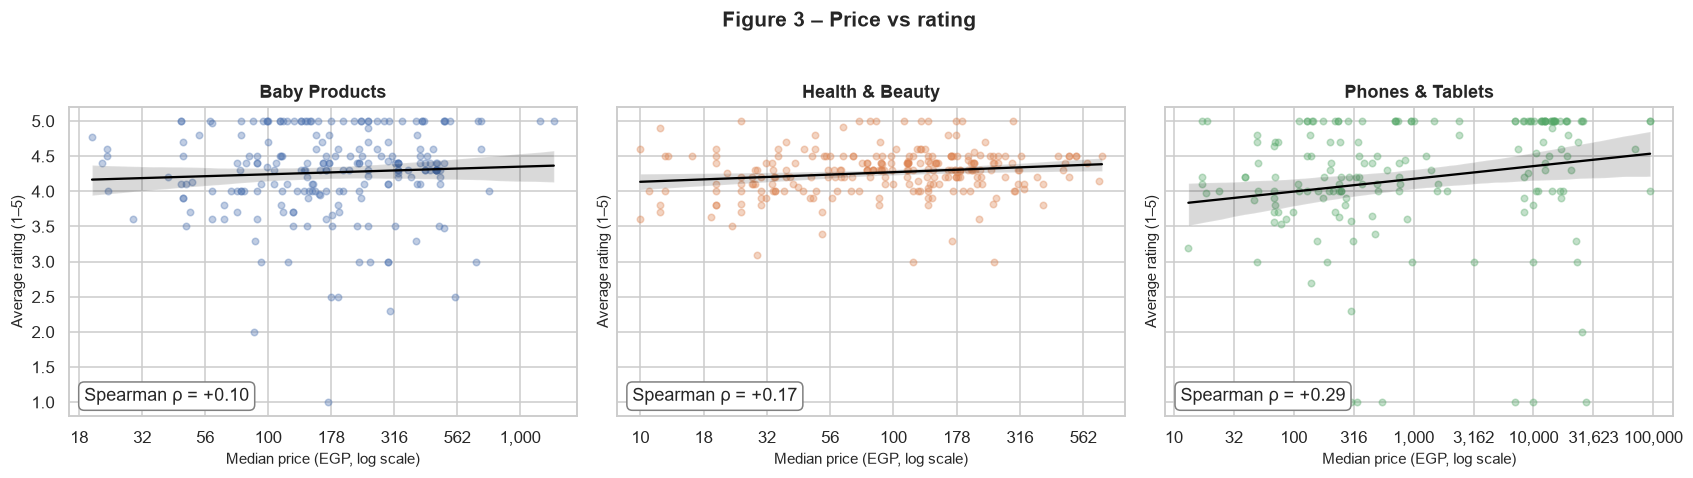

In [31]:
fig, axes = plt.subplots(1, len(CATS), figsize=(5.2 * len(CATS), 4.2), sharey=True, squeeze=False)
for ax, cat in zip(axes[0], CATS):
    g = rated[rated.category == cat]
    sns.regplot(data=g, x="log_price", y="mean_rating", ax=ax, color=PALETTE[cat],
                scatter_kws={"alpha": 0.35, "s": 18}, line_kws={"color": "black", "lw": 1.5})
    rho = price_rating.loc[cat, "rho_all"]
    ax.text(0.03, 0.05, f"Spearman ρ = {rho:+.2f}", transform=ax.transAxes,
            bbox=dict(boxstyle="round", fc="white", ec="grey"))
    ax.xaxis.set_major_formatter(log_fmt)
    ax.set_title(cat)
    ax.set_xlabel("Median price (EGP, log scale)")
    ax.set_ylabel("Average rating (1–5)")
    ax.set_ylim(0.8, 5.2)
fig.suptitle("Figure 3 – Price vs rating", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig03_price_vs_rating")

**Review count vs rank (popularity).** A product's *rank* is its position in the category list (1 = shown first). If popular products collect more reviews we expect **a negative ρ** (more reviews → smaller rank number). Reviews build up over time, so we use each product's **highest** review count and its **average** rank across the days it was seen.

,n_products,rho,p_value
category,,,
Baby Products,217,-0.50,0.00
Health & Beauty,250,-0.32,0.00
Phones & Tablets,177,-0.25,0.00


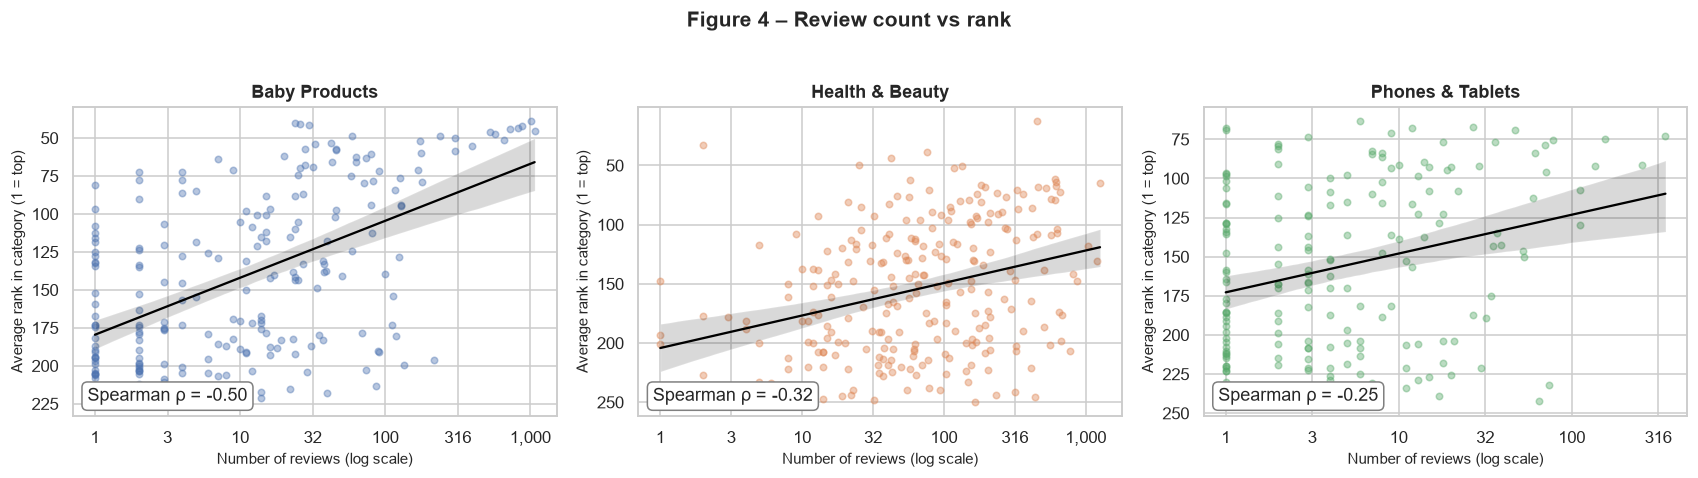

In [32]:
rev = prod.dropna(subset=["max_reviews"]).copy()
rev["log_reviews"] = np.log10(rev.max_reviews)

rows = []
for cat, g in rev.groupby("category"):
    rho, p = stats.spearmanr(g.max_reviews, g.mean_rank)
    rows.append({"category": cat, "n_products": len(g), "rho": rho, "p_value": p})
reviews_rank = pd.DataFrame(rows).set_index("category")
display(reviews_rank)

fig, axes = plt.subplots(1, len(CATS), figsize=(5.2 * len(CATS), 4.2), sharey=False, squeeze=False)
for ax, cat in zip(axes[0], CATS):
    g = rev[rev.category == cat]
    ax.scatter(g.log_reviews, g.mean_rank, s=18, alpha=0.4, color=PALETTE[cat])
    sns.regplot(data=g, x="log_reviews", y="mean_rank", scatter=False, ax=ax, color="black", line_kws={"lw": 1.5})
    ax.invert_yaxis()                                  # rank 1 at the top
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{10**x:,.0f}"))
    rho = reviews_rank.loc[cat, "rho"]
    ax.text(0.03, 0.05, f"Spearman ρ = {rho:+.2f}", transform=ax.transAxes,
            bbox=dict(boxstyle="round", fc="white", ec="grey"))
    ax.set_title(cat)
    ax.set_xlabel("Number of reviews (log scale)")
    ax.set_ylabel("Average rank in category (1 = top)")
fig.suptitle("Figure 4 – Review count vs rank", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig04_reviews_vs_rank")

## 6. Core question (c) – How did prices, discounts and rankings change over the collection period? Which products moved most?

**Step 6.1 – Daily summary per category.**
Remember from Step 3.2 which days have no run: the lines below connect the days that *do* exist, so a gap in dates shows up as a longer segment.

In [33]:
daily = (df.groupby(["date", "category"])
           .agg(products=("product_id", "nunique"),
                median_price=("price_egp", "median"),
                mean_price=("price_egp", "mean"),
                pct_discounted=("is_discounted", lambda s: 100 * s.mean()),
                avg_discount_pct=("discount_pct", "mean"))
           .reset_index())
daily

,date,category,products,median_price,mean_price,pct_discounted,avg_discount_pct
0,2026-10-13,Baby Products,224,179.50,243.42,94.64,29.38
1,2026-10-13,Health & Beauty,249,137.50,168.61,97.19,36.92
2,2026-10-13,Phones & Tablets,238,713.27,"10,816.05",90.76,33.64
3,2026-10-14,Baby Products,224,177.00,243.65,94.20,30.08
4,2026-10-14,Health & Beauty,199,115.00,145.68,97.99,35.90
5,2026-10-14,Phones & Tablets,240,699.00,"11,644.89",91.67,31.29
6,2026-10-15,Baby Products,224,174.00,239.41,93.75,30.04
7,2026-10-15,Health & Beauty,250,135.00,173.01,97.60,38.60
8,2026-10-15,Phones & Tablets,236,494.00,"10,499.47",91.95,31.43
9,2026-10-17,Baby Products,222,175.50,254.60,93.24,29.97


**Step 6.2 – Price trend.** Two views:

* **Left – median price per day.** Simple, but it can move just because *different products* were scraped on different days (the lists are not identical every day).
* **Right – same-basket price index.** We follow only the products seen on **every** collection day, set each product's first price to 100, and average. This isolates *real* price movement from changes in which products were captured.

Same-basket products (seen on all 6 days): 398


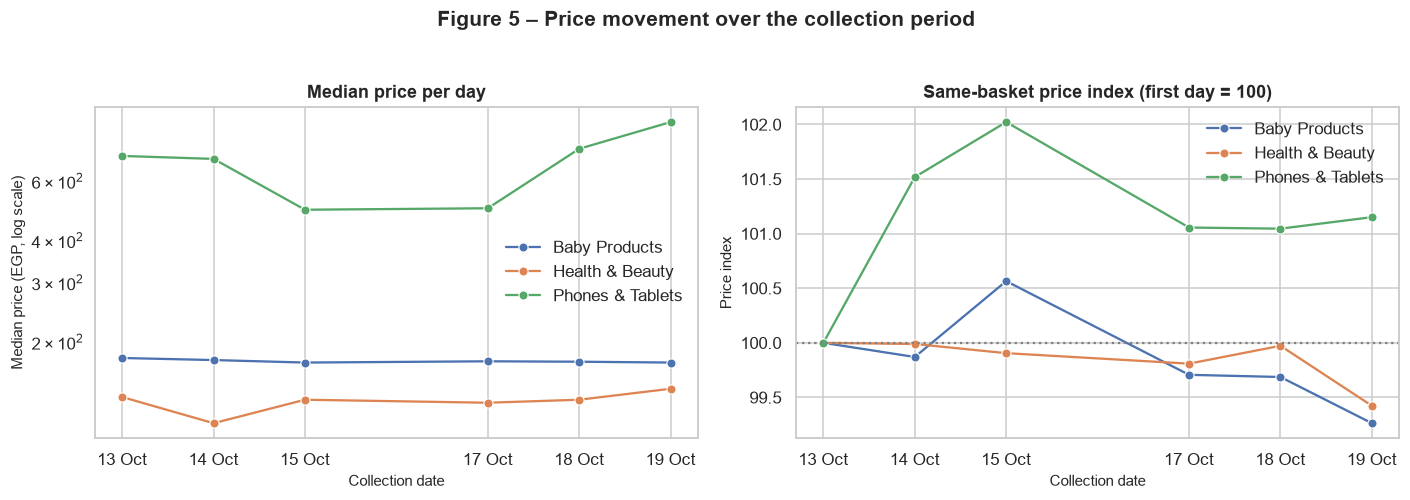

In [34]:
n_days = df.date.nunique()
seen_days = df.groupby("product_id").date.nunique()
basket_ids = seen_days[seen_days == n_days].index
print(f"Same-basket products (seen on all {n_days} days): {len(basket_ids):,}")

bp = df[df.product_id.isin(basket_ids)].sort_values(["product_id", "date"]).copy()
bp["price_index"] = 100 * bp.price_egp / bp.groupby("product_id").price_egp.transform("first")
index_daily = bp.groupby(["date", "category"]).price_index.mean().reset_index()

date_fmt = mdates.DateFormatter("%d %b")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.lineplot(data=daily, x="date", y="median_price", hue="category", palette=PALETTE,
             marker="o", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Median price per day")
axes[0].set_ylabel("Median price (EGP, log scale)")
sns.lineplot(data=index_daily, x="date", y="price_index", hue="category", palette=PALETTE,
             marker="o", ax=axes[1])
axes[1].axhline(100, color="grey", ls=":")
axes[1].set_title("Same-basket price index (first day = 100)")
axes[1].set_ylabel("Price index")
for ax in axes:
    ax.set_xticks(DATES); ax.xaxis.set_major_formatter(date_fmt); ax.set_xlabel("Collection date")
    ax.legend(title="", frameon=False)
fig.suptitle("Figure 5 – Price movement over the collection period", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig05_price_trend")

**Step 6.3 – Discount trend.** How much of each category was on discount each day, and how deep were the discounts (average discount among discounted products)?

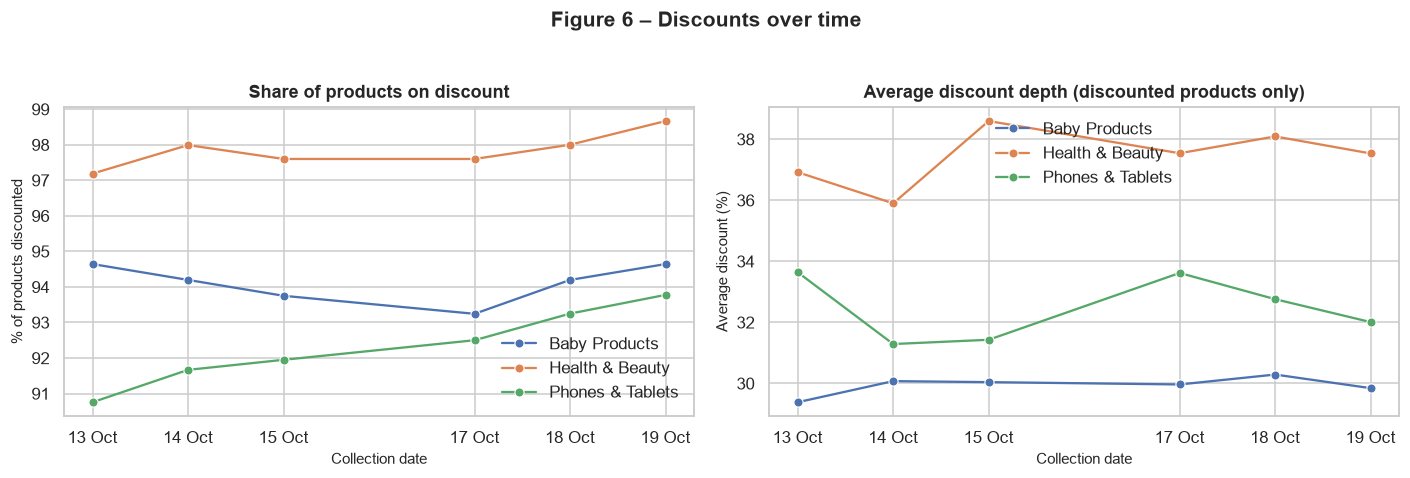

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.lineplot(data=daily, x="date", y="pct_discounted", hue="category", palette=PALETTE, marker="o", ax=axes[0])
axes[0].set_title("Share of products on discount")
axes[0].set_ylabel("% of products discounted")
sns.lineplot(data=daily, x="date", y="avg_discount_pct", hue="category", palette=PALETTE, marker="o", ax=axes[1])
axes[1].set_title("Average discount depth (discounted products only)")
axes[1].set_ylabel("Average discount (%)")
for ax in axes:
    ax.set_xticks(DATES); ax.xaxis.set_major_formatter(date_fmt); ax.set_xlabel("Collection date")
    ax.legend(title="", frameon=False)
fig.suptitle("Figure 6 – Discounts over time", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig06_discount_trend")

**Step 6.4 – Which products moved most?**
For every product seen on at least two days we compare its **first** and **last** observation:

* `price_change_pct` = (last price − first price) / first price × 100
* `rank_change` = first rank − last rank → **positive = moved up the list** (closer to rank 1)

In [36]:
i_first = df.groupby("product_id").date.idxmin()
i_last  = df.groupby("product_id").date.idxmax()
cols = ["product_id", "name", "category", "date", "price_egp", "rank_in_category"]
f = df.loc[i_first.values, cols].set_index("product_id")
l = df.loc[i_last.values,  cols].set_index("product_id")

mv = f.join(l[["date", "price_egp", "rank_in_category"]], lsuffix="_first", rsuffix="_last")
mv = mv[mv.date_first < mv.date_last].copy()
mv["price_change_pct"] = 100 * (mv.price_egp_last - mv.price_egp_first) / mv.price_egp_first
mv["rank_change"] = mv.rank_in_category_first - mv.rank_in_category_last
mv["price_changed"] = mv.price_change_pct.abs() > 0.01

move_summary = (mv.groupby("category")
                  .agg(products_tracked=("name", "count"),
                       pct_changed_price=("price_changed", lambda s: 100 * s.mean()),
                       pct_price_up=("price_change_pct", lambda s: 100 * (s > 0.01).mean()),
                       pct_price_down=("price_change_pct", lambda s: 100 * (s < -0.01).mean()),
                       avg_price_change_pct=("price_change_pct", "mean"),
                       avg_abs_rank_change=("rank_change", lambda s: s.abs().mean())))
display(move_summary)

,products_tracked,pct_changed_price,pct_price_up,pct_price_down,avg_price_change_pct,avg_abs_rank_change
category,,,,,,
Baby Products,250,10.40,2.40,8.00,0.15,20.14
Health & Beauty,283,13.07,5.30,7.77,-0.32,18.06
Phones & Tablets,285,32.28,18.95,13.33,0.95,18.00


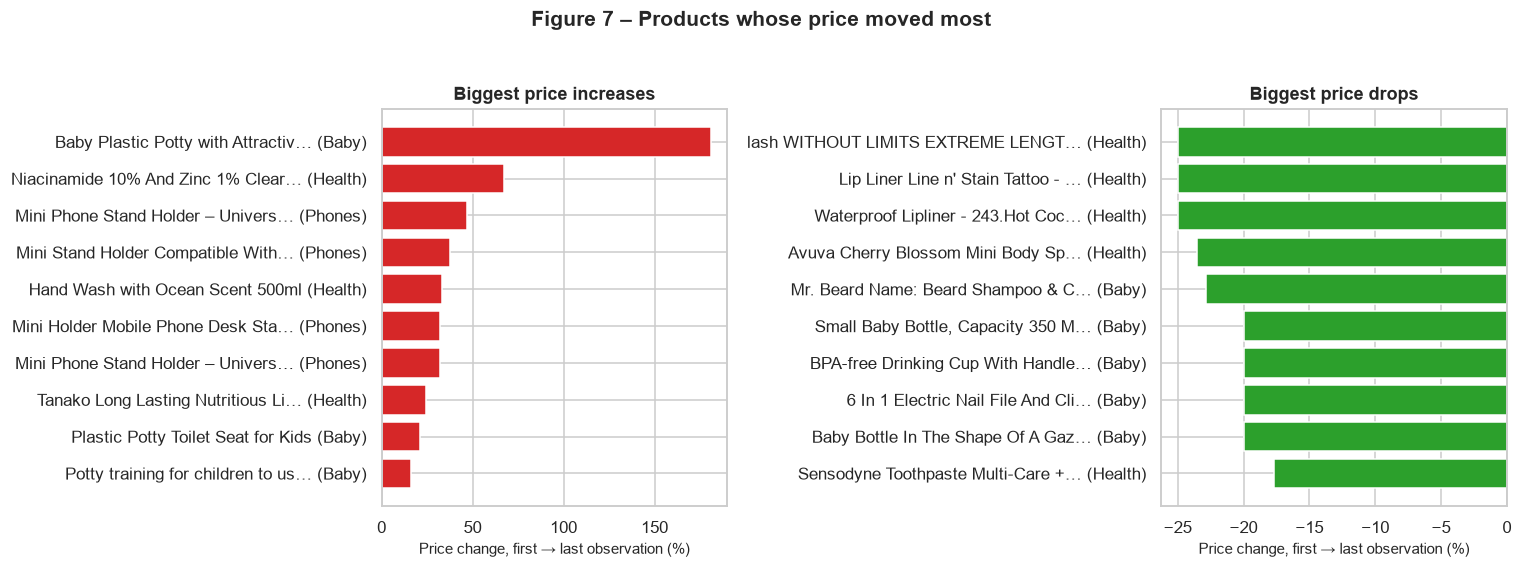

,name,category,price_egp_first,price_egp_last,price_change_pct
product_id,,,,,
GE810ST2SZTXBNAFAMZ,Baby Plastic Potty with Attractive and Safe De...,Baby Products,89.00,250.00,180.90
TH199ST2WQ1V1NAFAMZ,Niacinamide 10% And Zinc 1% Clear 30ml,Health & Beauty,449.10,750.00,67.00
GE810EA2L5JQPNAFAMZ,Mini Phone Stand Holder – Universal Adjustable...,Phones & Tablets,17.00,25.00,47.06
GE810EA0TARAUNAFAMZ,Mini Stand Holder Compatible With All Smart Ph...,Phones & Tablets,17.00,23.40,37.65
BR692ST2JKNIBNAFAMZ,Hand Wash with Ocean Scent 500ml,Health & Beauty,45.00,60.00,33.33
GE810EA13R0SPNAFAMZ,"Mini Holder Mobile Phone Desk Stand, Adjustabl...",Phones & Tablets,17.00,22.50,32.35
GE810EA2LOUSDNAFAMZ,Mini Phone Stand Holder – Universal Adjustable...,Phones & Tablets,17.00,22.50,32.35
TA622ST14CEONNAFAMZ,Tanako Long Lasting Nutritious Lip Balm,Health & Beauty,22.50,28.00,24.44
GE810ST2XDV1NNAFAMZ,Plastic Potty Toilet Seat for Kids,Baby Products,94.99,115.00,21.07


In [37]:
def label(row):
    return f"{short(row['name'], 34)} ({row['category'].split()[0]})"

ups   = mv.nlargest(10, "price_change_pct")
downs = mv.nsmallest(10, "price_change_pct")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
barh_labeled(axes[0], [label(r) for _, r in ups.iterrows()], ups.price_change_pct, "#d62728")
axes[0].set_title("Biggest price increases")
barh_labeled(axes[1], [label(r) for _, r in downs.iterrows()], downs.price_change_pct, "#2ca02c")
axes[1].set_title("Biggest price drops")
for ax in axes:
    ax.set_xlabel("Price change, first → last observation (%)")
fig.suptitle("Figure 7 – Products whose price moved most", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig07_price_movers")

display(pd.concat([ups, downs])[["name", "category", "price_egp_first", "price_egp_last", "price_change_pct"]]
        .assign(name=lambda d: d["name"].map(lambda s: short(s, 50))))

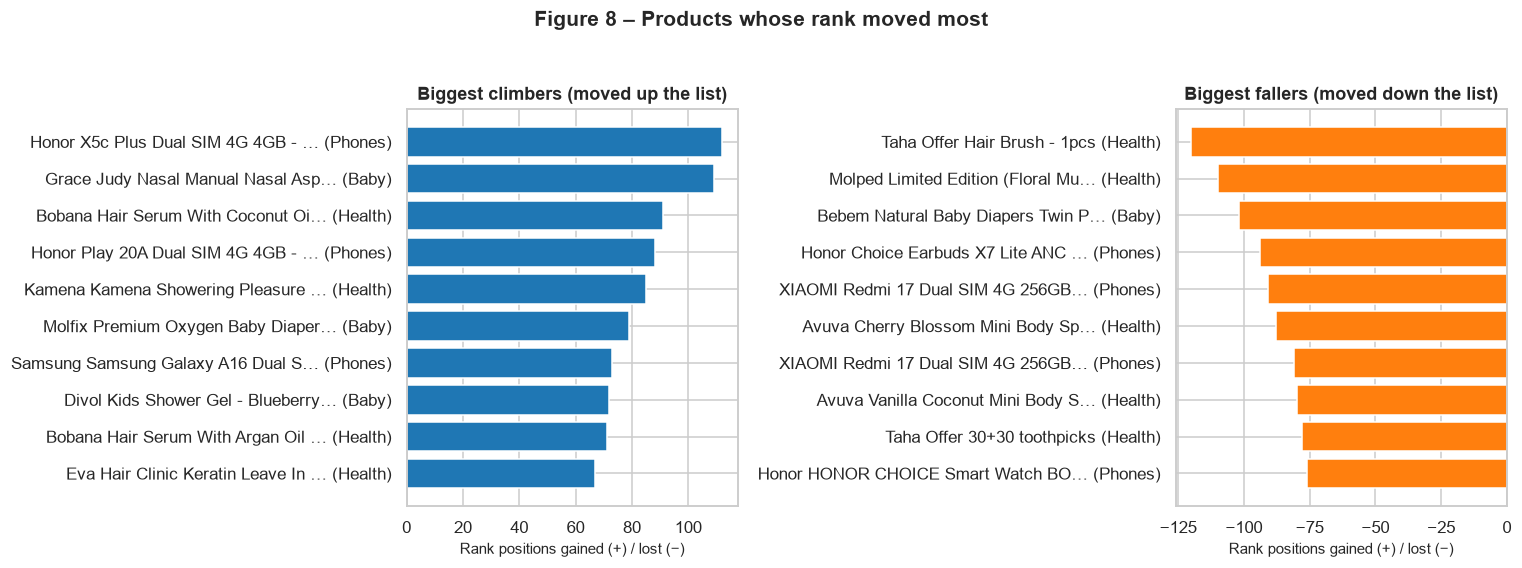

,name,category,rank_in_category_first,rank_in_category_last,rank_change
product_id,,,,,
HO474MP33DZOPNAFAMZ,Honor X5c Plus Dual SIM 4G 4GB - 128GB - Midni...,Phones & Tablets,228,116,112
GR939ST207Z13NAFAMZ,Grace Judy Nasal Manual Nasal Aspirator for Ch...,Baby Products,201,92,109
BO212ST3A5NW5NAFAMZ,Bobana Hair Serum With Coconut Oil 100 ML,Health & Beauty,242,151,91
HO474MP2WG6PHNAFAMZ,Honor Play 20A Dual SIM 4G 4GB - 64GB - Light ...,Phones & Tablets,226,138,88
KA738ST2WRB78NAFAMZ,Kamena Kamena Showering Pleasure Peaches Perfu...,Health & Beauty,244,159,85
MO711DI1UT9TPNAFAMZ,Molfix Premium Oxygen Baby Diapers - Jumbo Pac...,Baby Products,178,99,79
SA024MP1SH75FNAFAMZ,"Samsung Samsung Galaxy A16 Dual SIM, 128GB, 4G...",Phones & Tablets,198,125,73
BR881ST211QA0NAFAMZ,Divol Kids Shower Gel - Blueberry - 300 Ml,Baby Products,219,147,72
BO212ST2Y8ZSLNAFAMZ,Bobana Hair Serum With Argan Oil 100 ML,Health & Beauty,74,3,71


In [38]:
climbers = mv.nlargest(10, "rank_change")
fallers  = mv.nsmallest(10, "rank_change")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
barh_labeled(axes[0], [label(r) for _, r in climbers.iterrows()], climbers.rank_change, "#1f77b4")
axes[0].set_title("Biggest climbers (moved up the list)")
barh_labeled(axes[1], [label(r) for _, r in fallers.iterrows()], fallers.rank_change, "#ff7f0e")
axes[1].set_title("Biggest fallers (moved down the list)")
for ax in axes:
    ax.set_xlabel("Rank positions gained (+) / lost (−)")
fig.suptitle("Figure 8 – Products whose rank moved most", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig08_rank_movers")

display(pd.concat([climbers, fallers])[["name", "category", "rank_in_category_first", "rank_in_category_last", "rank_change"]]
        .assign(name=lambda d: d["name"].map(lambda s: short(s, 50))))

> **Caution when you interpret rank changes:** the category lists are not exactly the same length every day (some pages return fewer items on some runs), and products that disappear from the list are not tracked here. Treat large rank moves as *signals worth explaining*, not proof of a change in demand.

## 7. Core question (d) – Which brands or sellers dominate each category?

Jumia's listing pages give us the **brand**, not the seller. Many items are branded `Generic` (unbranded marketplace goods), so we report it separately and then look at the dominance of **named brands**. Two views of dominance:

1. **Catalogue share** – the share of distinct products carrying each brand.
2. **Visibility share** – the share of the **top-50 positions** on the most recent collection day.

In [39]:
UNBRANDED = {"Generic", "Unknown"}

brand_cnt = (prod.groupby(["category", "brand"]).product_id.nunique().rename("n_products").reset_index())
brand_cnt["share_pct"] = 100 * brand_cnt.n_products / brand_cnt.groupby("category").n_products.transform("sum")

conc = []
for cat, g in brand_cnt.groupby("category"):
    named = g[~g.brand.isin(UNBRANDED)].sort_values("n_products", ascending=False)
    total = g.n_products.sum()
    shares = named.n_products / total
    conc.append({"category": cat,
                 "distinct_brands": g.brand.nunique(),
                 "unbranded_share_%": 100 * g[g.brand.isin(UNBRANDED)].n_products.sum() / total,
                 "top1_brand": named.brand.iloc[0] if len(named) else "-",
                 "top3_named_share_%": 100 * shares.head(3).sum(),
                 "top10_named_share_%": 100 * shares.head(10).sum(),
                 "HHI_named (0-10000)": float((100 * shares).pow(2).sum())})
concentration = pd.DataFrame(conc).set_index("category")
concentration

,distinct_brands,unbranded_share_%,top1_brand,top3_named_share_%,top10_named_share_%,HHI_named (0-10000)
category,,,,,,
Baby Products,66,20.33,Molfix,19.33,38.33,251.00
Health & Beauty,102,11.85,Vacation,17.33,38.30,213.41
Phones & Tablets,37,37.12,Honor,24.10,47.92,304.71


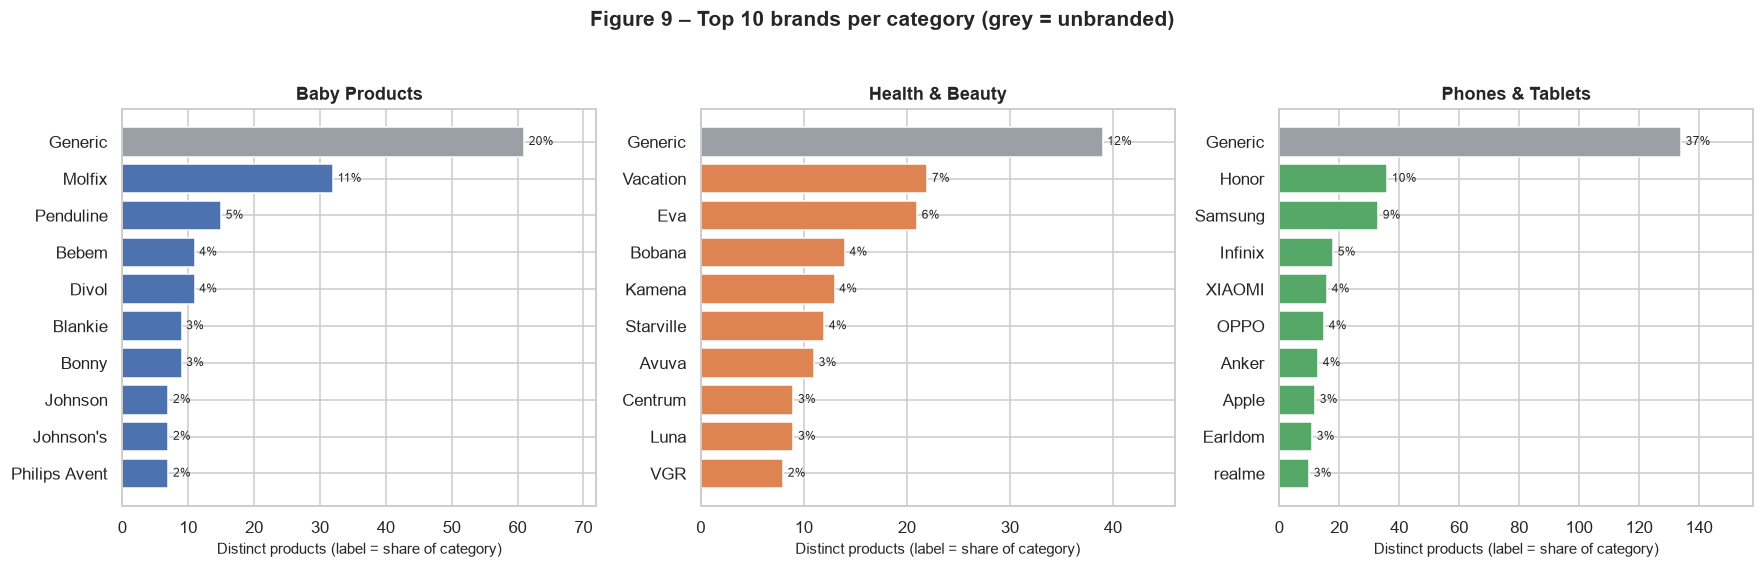

In [40]:
fig, axes = plt.subplots(1, len(CATS), figsize=(5.4 * len(CATS), 5), squeeze=False)
for ax, cat in zip(axes[0], CATS):
    top = brand_cnt[brand_cnt.category == cat].nlargest(10, "n_products").iloc[::-1]
    colors = ["#9aa0a6" if b in UNBRANDED else PALETTE[cat] for b in top.brand]
    bars = ax.barh(top.brand, top.n_products, color=colors)
    ax.bar_label(bars, labels=[f"{s:.0f}%" for s in top.share_pct], padding=3, fontsize=8)
    ax.set_title(cat)
    ax.set_xlabel("Distinct products (label = share of category)")
    ax.set_xlim(0, top.n_products.max() * 1.18)
fig.suptitle("Figure 9 – Top 10 brands per category (grey = unbranded)", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig09_brand_dominance")

In [41]:
latest_date = df.date.max()
top50 = df[(df.date == latest_date) & (df.rank_in_category <= 50)]
vis = (top50.groupby(["category", "brand"]).size().rename("slots_in_top50").reset_index())
vis["share_of_top50_%"] = 100 * vis.slots_in_top50 / vis.groupby("category").slots_in_top50.transform("sum")
print(f"Visibility: who holds the top-50 positions on {latest_date:%d %b %Y}")
for cat in CATS:
    display(vis[vis.category == cat].nlargest(5, "slots_in_top50").set_index("brand")
            [["slots_in_top50", "share_of_top50_%"]].rename_axis(cat))

Visibility: who holds the top-50 positions on 19 Oct 2026


,slots_in_top50,share_of_top50_%
Baby Products,,
Generic,17,34.00
Molfix,8,16.00
Genetic,4,8.00
Toffee Kids,4,8.00
Blankie,3,6.00


,slots_in_top50,share_of_top50_%
Health & Beauty,,
Might Cinema,4,8.00
Bobana,3,6.00
Generic,3,6.00
SOVA,3,6.00
Starville,3,6.00


,slots_in_top50,share_of_top50_%
Phones & Tablets,,
Generic,15,30.00
Apple,6,12.00
Anker,4,8.00
Honor,4,8.00
Earldom,3,6.00


## 8. Core question (e) – What share of products are discounted, and how large are the discounts *really*?

**Step 8.1 – How common and how deep.** A product counts as *discounted* when the site shows a discount badge. The discount depth is taken from the site's stated percentage.

In [42]:
disc = (df.groupby("category")
          .agg(observations=("obs_id", "count"),
               share_discounted_pct=("is_discounted", lambda s: 100 * s.mean()),
               mean_discount_pct=("discount_pct", "mean"),
               median_discount_pct=("discount_pct", "median"),
               p90_discount_pct=("discount_pct", lambda s: s.quantile(.9)),
               max_discount_pct=("discount_pct", "max")))
display(disc)

bands = pd.cut(df.loc[df.is_discounted == 1, "discount_pct"],
               bins=[0, 10, 20, 30, 40, 50, 100],
               labels=["≤10%", "10–20%", "20–30%", "30–40%", "40–50%", ">50%"])
band_share = pd.crosstab(df.loc[df.is_discounted == 1, "category"], bands, normalize="index") * 100
band_share

,observations,share_discounted_pct,mean_discount_pct,median_discount_pct,p90_discount_pct,max_discount_pct
category,,,,,,
Baby Products,1342,94.11,29.93,29.90,53.30,79.50
Health & Beauty,1348,97.77,37.48,36.40,59.53,90.80
Phones & Tablets,1432,92.32,32.46,23.60,71.00,88.70


discount_pct,≤10%,10–20%,20–30%,30–40%,40–50%,>50%
category,,,,,,
Baby Products,7.21,20.59,24.86,29.14,6.49,11.72
Health & Beauty,2.88,8.19,26.86,23.60,23.07,15.40
Phones & Tablets,27.61,18.23,8.47,10.29,8.17,27.23


**Step 8.2 – Can we trust the discount?** A "real" discount means the **old price** was a genuine earlier price. We test three things:

1. **Is the badge consistent with the prices?** Where both old and new price are shown we recompute `(old − new) / old` and compare with the badge.
2. **How often can we check at all?** Some discounted items show a badge but *no* old price.
3. **Was the old price ever seen as a selling price?** If the highest price we ever recorded for a product (over all days) is far below its "old price", then at least within our collection window the product never sold at that old price. This does **not prove** the old price is fake (it may come from before we started scraping). But if almost every product is "on sale" for the whole week, the old price behaves like a permanent *reference price* rather than a temporary markdown, which is worth discussing in the report.

In [43]:
has_badge = df[df.is_discounted == 1].copy()

# 1) badge vs recomputed discount
both = has_badge.dropna(subset=["old_price_egp"]).copy()
both["computed_pct"] = 100 * (1 - both.price_egp / both.old_price_egp)
gap = (both.computed_pct - both.discount_pct).abs()
print(f"1) Rows with both prices: {len(both):,}. Largest gap between recomputed and stated discount: {gap.max():.2f} percentage points "
      f"(median {gap.median():.3f}).")

# 2) how often the old price is missing
check = (has_badge.groupby("category")
         .agg(discounted_rows=("obs_id", "count"),
              old_price_shown_pct=("old_price_egp", lambda s: 100 * s.notna().mean())))
check["badge_without_old_price_pct"] = 100 - check.old_price_shown_pct

# 3) was the old price ever a selling price?
max_seen = df.groupby("product_id").price_egp.max().rename("max_price_seen")
both = both.join(max_seen, on="product_id")
both["old_price_seen_as_price"] = both.max_price_seen >= 0.98 * both.old_price_egp
check["old_price_ever_observed_pct"] = both.groupby("category").old_price_seen_as_price.mean() * 100

# bonus: does the reference (old) price itself change?
old_changes = df.dropna(subset=["old_price_egp"]).groupby("product_id").old_price_egp.nunique()
print(f"3) Products whose old price changed during the window: {100*(old_changes>1).mean():.1f}% of {len(old_changes):,}")
check

1) Rows with both prices: 2,979. Largest gap between recomputed and stated discount: 0.05 percentage points (median 0.020).
3) Products whose old price changed during the window: 3.9% of 743


,discounted_rows,old_price_shown_pct,badge_without_old_price_pct,old_price_ever_observed_pct
category,,,,
Baby Products,1263,82.11,17.89,1.93
Health & Beauty,1318,72.99,27.01,0.10
Phones & Tablets,1322,74.13,25.87,1.63


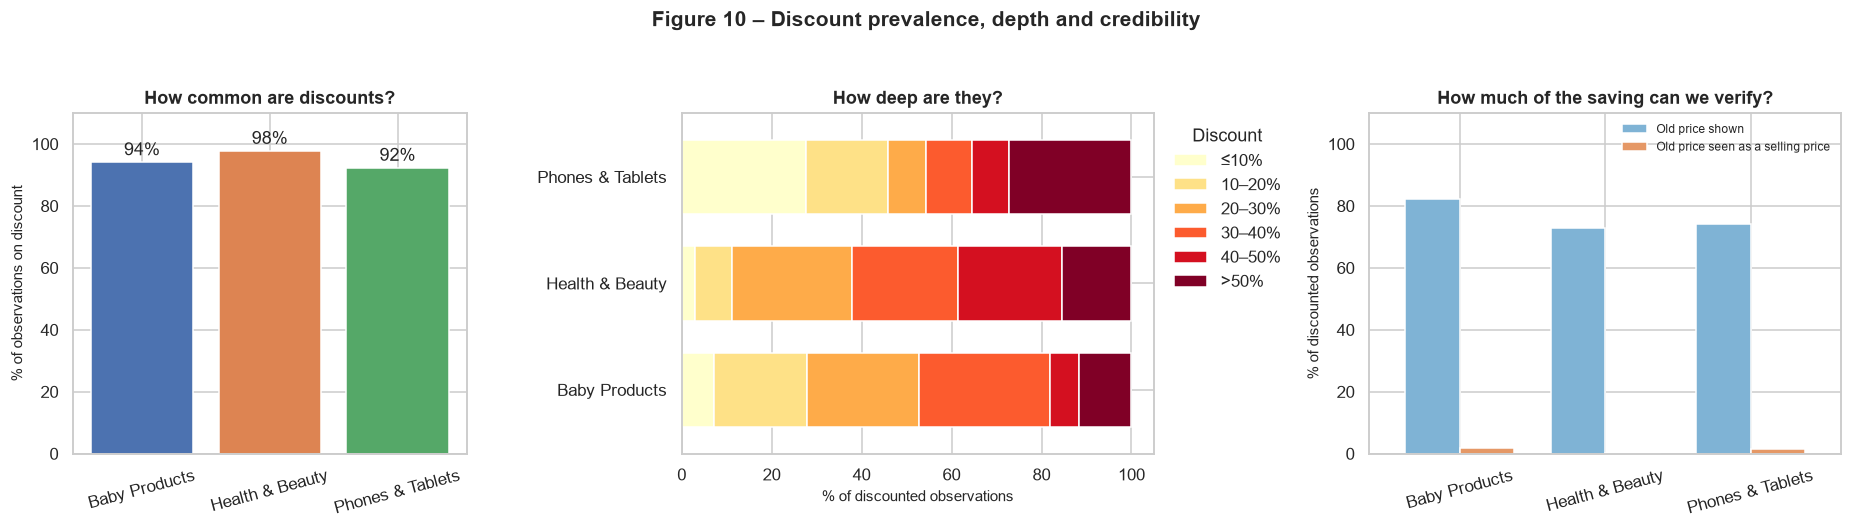

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.2, 1.2]})

# (1) share discounted
bars = axes[0].bar(disc.index, disc.share_discounted_pct, color=[PALETTE[c] for c in disc.index])
axes[0].bar_label(bars, labels=[f"{v:.0f}%" for v in disc.share_discounted_pct], padding=2)
axes[0].set_ylim(0, 110); axes[0].set_ylabel("% of observations on discount")
axes[0].set_title("How common are discounts?")
axes[0].tick_params(axis="x", rotation=15)

# (2) discount size bands
band_share.plot(kind="barh", stacked=True, ax=axes[1], colormap="YlOrRd", width=0.7)
axes[1].set_xlabel("% of discounted observations"); axes[1].set_ylabel("")
axes[1].set_title("How deep are they?")
axes[1].legend(title="Discount", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

# (3) verification
v = check[["old_price_shown_pct", "old_price_ever_observed_pct"]].rename(
    columns={"old_price_shown_pct": "Old price shown", "old_price_ever_observed_pct": "Old price seen as a selling price"})
v.plot(kind="bar", ax=axes[2], color=["#7fb3d5", "#e59866"], width=0.75)
axes[2].set_ylim(0, 110); axes[2].set_ylabel("% of discounted observations")
axes[2].set_title("How much of the saving can we verify?")
axes[2].tick_params(axis="x", rotation=15); axes[2].set_xlabel("")
axes[2].legend(frameon=False, fontsize=8)
fig.suptitle("Figure 10 – Discount prevalence, depth and credibility", fontsize=14, fontweight="bold", y=1.04)
finish(fig, "fig10_discounts")

## 9. Our own question – *Do deeper discounts buy better visibility?*

**Why this question:** sellers pay for discounts, so it is worth asking whether the site rewards them with a better position in the list (and therefore more exposure). We look at it in two ways:

1. **Across products:** are products with deeper average discounts placed nearer the top of their category list? (average rank, 1 = top)
2. **Within a product over time:** when a product's price was **cut** between two consecutive runs, did its rank improve compared with products whose price did not change?

*These are associations, not proof of cause and effect* (a product may be cut in price because it is already popular, or the site may rank by something we cannot see). In part 2, "rank improvement" = previous rank − new rank, so **+10 means the product moved 10 places closer to the top**. Compare the price-cut groups with the **"No change" group**, which is the baseline.

In [1]:
# ---- (1) across products
rows = []
for cat, g in prod.groupby("category"):
    rho, p = stats.spearmanr(g.mean_discount, g.mean_rank)
    rows.append({"category": cat, "n_products": len(g), "rho": rho, "p_value": p})
disc_vs_rank = pd.DataFrame(rows).set_index("category")
display(disc_vs_rank)

prod["discount_band"] = pd.cut(prod.mean_discount, bins=[-0.01, 0.01, 20, 40, 100],
                               labels=["None", "1–20%", "20–40%", ">40%"])

# ---- (2) within a product between consecutive runs
ps = df.sort_values(["product_id", "date"]).copy()
ps["prev_price"] = ps.groupby("product_id").price_egp.shift()
ps["prev_rank"] = ps.groupby("product_id").rank_in_category.shift()
pairs = ps.dropna(subset=["prev_price"]).copy()
pairs["price_chg_pct"] = 100 * (pairs.price_egp - pairs.prev_price) / pairs.prev_price
pairs["rank_improvement"] = pairs.prev_rank - pairs.rank_in_category    # + = moved toward the top (rank 1)
buckets = ["Cut >5%", "Cut 0.5–5%", "No change", "Rise 0.5–5%", "Rise >5%"]
pairs["price_move"] = pd.cut(pairs.price_chg_pct, [-np.inf, -5, -0.5, 0.5, 5, np.inf], labels=buckets)

move_table = (pairs.groupby("price_move", observed=True).rank_improvement
              .agg(pairs="count", mean="mean", median="median"))
display(move_table)

cut = pairs.loc[pairs.price_move == "Cut >5%", "rank_improvement"].dropna()
same = pairs.loc[pairs.price_move == "No change", "rank_improvement"].dropna()
if len(cut) > 5 and len(same) > 5:
    u, p = stats.mannwhitneyu(cut, same, alternative="two-sided")
    print(f"Mann-Whitney U, 'Cut >5%' (n={len(cut)}) vs 'No change' (n={len(same)}): p = {p:.4f}")

NameError: name 'prod' is not defined

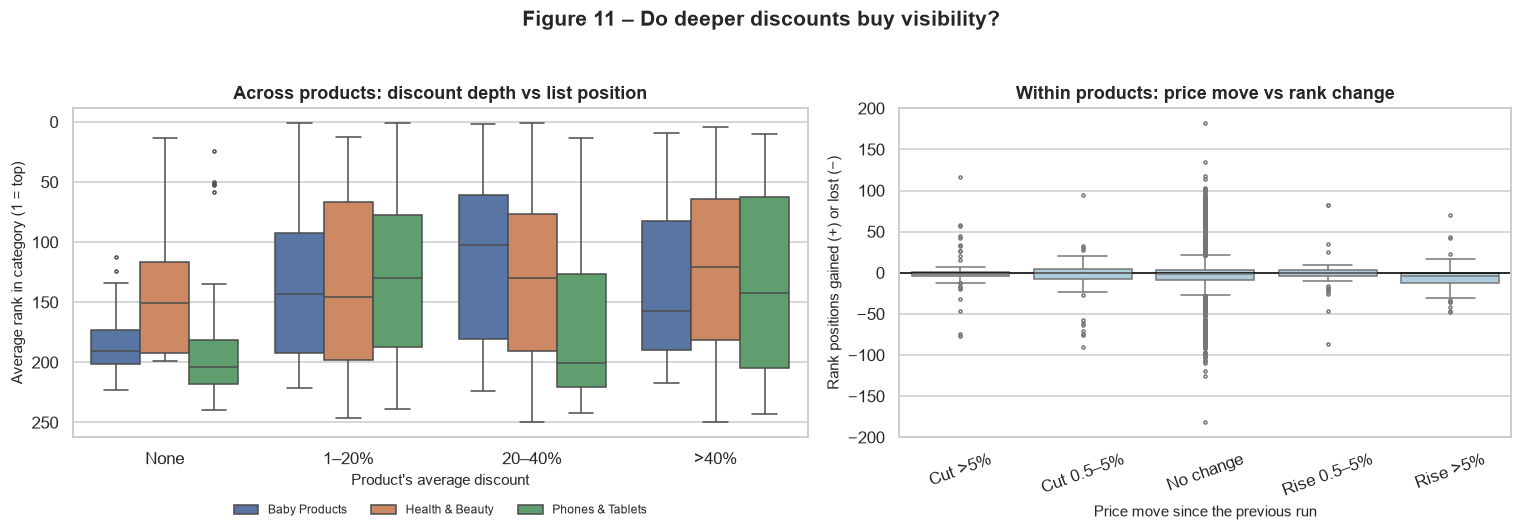

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
sns.boxplot(data=prod, x="discount_band", y="mean_rank", hue="category", hue_order=CATS,
            palette=PALETTE, ax=axes[0], fliersize=2)
axes[0].invert_yaxis()
axes[0].set_xlabel("Product's average discount"); axes[0].set_ylabel("Average rank in category (1 = top)")
axes[0].set_title("Across products: discount depth vs list position")
axes[0].legend(title="", frameon=False, fontsize=8, loc="upper center",
               bbox_to_anchor=(0.5, -0.17), ncol=len(CATS))

sns.boxplot(data=pairs, x="price_move", y="rank_improvement", order=buckets, color="#a6cee3",
            ax=axes[1], fliersize=2)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Price move since the previous run"); axes[1].set_ylabel("Rank positions gained (+) or lost (−)")
axes[1].set_title("Within products: price move vs rank change")
axes[1].tick_params(axis="x", rotation=20)
fig.suptitle("Figure 11 – Do deeper discounts buy visibility?", fontsize=14, fontweight="bold", y=1.03)
finish(fig, "fig11_discount_vs_visibility")

### Written interpretation (complete this in your own words)

(a) Price distribution & outliers Fig. 1–2, 
outlier table  Price distribution by category (log scale). Prices span orders of magnitude, so the histograms use a logarithmic axis; on a linear axis nearly every product would collapse into a single bar. All three categories are strongly right-skewed, with the mean sitting far above the median. Median prices are 173.50 EGP (Baby Products), 127.00 EGP (Health & Beauty) and 499.00 EGP (Phones & Tablets), while the means are 252.22, 157.80 and 9,592.04 EGP. The Phones & Tablets panel is clearly bimodal — a large mass of cheap accessories alongside a small band of premium handsets.

(b) Price ↔ rating, reviews ↔ rank Fig. 3–4, correlation tables
 Rank is the product's position in the site's category list (1 = top), so the question is whether more reviews buy a better position. The correlation is negative and statistically significant in all three categories: −0.50 (Baby Products), −0.32 (Health & Beauty) and −0.25 (Phones & Tablets), all p < 0.01. Review count is therefore a usable, if imperfect, proxy for visibility — and it is also the field with the most missing values, which is why the number of products behind every coefficient is reported. The weakest relationship appears in Phones & Tablets, where a handful of premium handsets gather most of the reviews.

(c) Change over the days, biggest movers: Fig. 5–8, movers tables
Price movement over the collection period. The left panel (median price per day) visibly moves, but the right panel (same-basket price index, built only from the 398 products seen on all six days) stays flat. That contrast proves the daily medians shift because the mix of scraped products changes, not because shop prices change. The average same-basket change was just +0.15% in Baby Products, −0.32% in Health & Beauty and +0.95% in Phones & Tablets. Note the gap in the x-axis: there was no run on 16 October, so the line jumps a day.

(d) Brand dominance: Fig. 9, concentration table
Top ten brands per category. The catalogue is fragmented but visibly unbranded: 20.3% of Baby Products, 11.9% of Health & Beauty and 37.1% of Phones & Tablets carry no brand name at all. Health & Beauty is the most fragmente with no single named brand reaching even a fifth of it; Phones & Tablets is the most concentrated, but that concentration sits in unbranded goods. Molfix leads Baby Products, Vacation leads Health & Beauty and Honor leads Phones & Tablets. The visibility check agrees: on 19 October Generic held 17 of the top 50 slots in Baby Products and 15 in Phones & Tablets, with Apple taking 6 in Phones & Tablets and Molfix 8 in Baby Products.

(e) Discount share and real size:Fig. 10, verification table
 Discount prevalence, depth and credibility. Discounts are near-universal (92–98% of observations) with medians of 29.9%, 36.4% and 23.6%, and deepest single discounts of 79.5%, 90.8% and 88.7%. Where both prices are shown the badge matches the arithmetic exactly — across 2,979 rows the largest disagreement is 0.05 percentage points. The problem is the old price itself: displayed for only 82.1%, 73.0% and 74.1% of discounted rows, and observed as an actual selling price for just 1.9%, 0.1% and 1.6% of them. Only 3.9% of the 743 products carrying an old price ever saw it change, so the "old price" behaves as a permanent reference price rather than a genuine markdown.

